In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

In [2]:
data.camera()

array([[200, 200, 200, ..., 189, 190, 190],
       [200, 199, 199, ..., 190, 190, 190],
       [199, 199, 199, ..., 190, 190, 190],
       ...,
       [ 25,  25,  27, ..., 139, 122, 147],
       [ 25,  25,  26, ..., 158, 141, 168],
       [ 25,  25,  27, ..., 151, 152, 149]], shape=(512, 512), dtype=uint8)

# 1 - Usando função interna

In [3]:
def implot (img, img_filtrada, kernelsize):
  plt.subplot(1, 2, 1)
  plt.imshow(img)
  plt.title('Imagem original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(img_filtrada)
  plt.title('filtro de media ' + kernelsize)
  plt.axis('off')

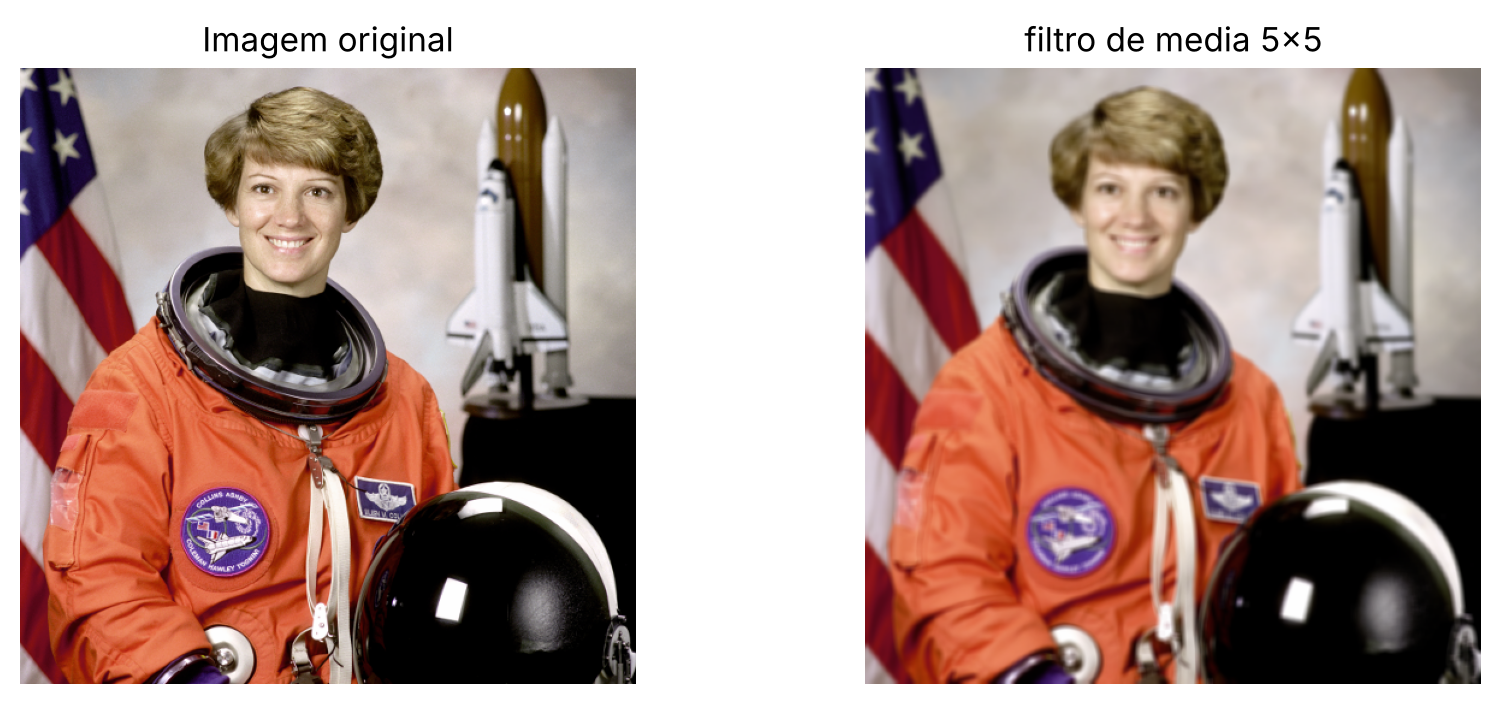

In [4]:
img = data.astronaut()
img_filtrada = cv2.blur(img, (5,5))

plt.figure(figsize=(10,4))
implot(img, img_filtrada, '5x5')

# Filtro de media

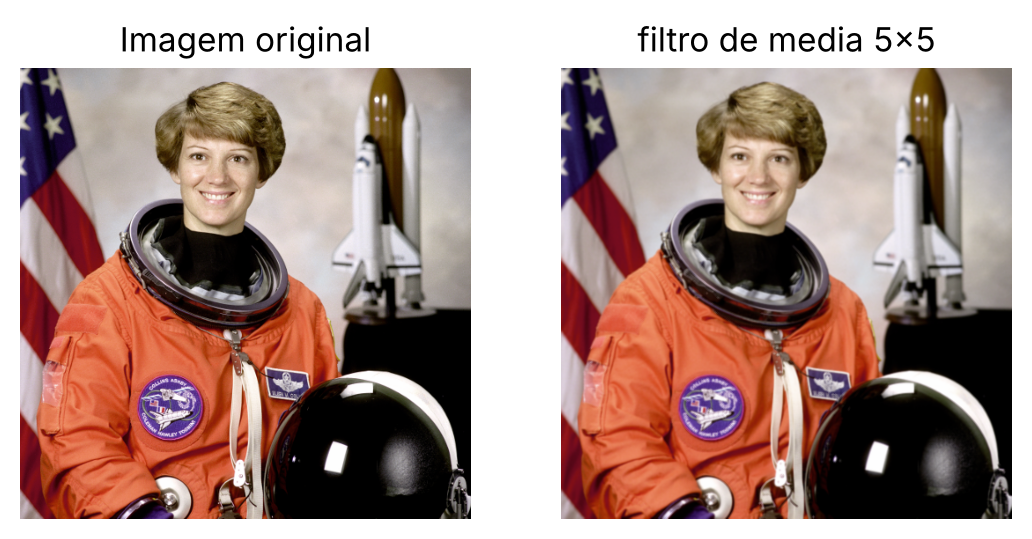

In [5]:
kernel = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
])

kernel = kernel / np.sum(kernel)

img_filtrada = cv2.filter2D(img, -1, kernel)
implot (img, img_filtrada, '5x5')

# Aguçameno

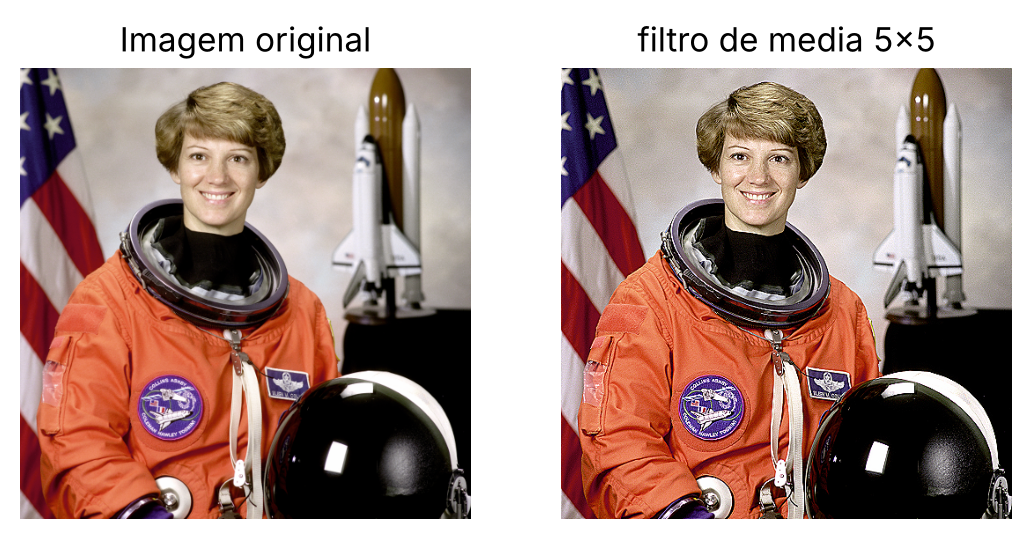

In [6]:
kernel = np.array([
    [  0, -1,  0],
    [ -1,  5, -1],
    [  0, -1,  0]
])

# kernel = kernel / np.sum(kernel) não é necessario normalizar

img_filtrada = cv2.filter2D(img, -1, kernel)
implot (img, img_filtrada, '5x5')

# 2 - Implementação manual dos filtros

Todos os filtros abaixo usam apenas NumPy. A convolução é feita manualmente, percorrendo cada pixel da imagem.

- **Linear:** Média (via convolução com kernel)
- **Não-lineares:** Mediana, Moda e Máxima (via janela deslizante)

In [7]:
from skimage import data

# Imagem de exemplo em escala de cinza
img_cinza = data.camera()
print(img_cinza.shape, img_cinza.dtype)

(512, 512) uint8


## Funções auxiliares: padding, convolução e janela deslizante

In [ ]:
def aplicar_padding(img, pad):
    return np.pad(img, pad, mode='edge')


def convolucao(img, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    kernel_inv = np.flip(kernel)  # convolução = correlação com o kernel invertido
    img_pad = aplicar_padding(img.astype(np.float64), ((ph, ph), (pw, pw)))

    altura, largura = img.shape
    saida = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            janela = img_pad[i:i + kh, j:j + kw]
            saida[i, j] = np.sum(janela * kernel_inv)

    return np.clip(np.round(saida), 0, 255).astype(np.uint8)


def janela_deslizante(img, tamanho, operacao):
    p = tamanho // 2
    img_pad = aplicar_padding(img, ((p, p), (p, p)))

    altura, largura = img.shape
    saida = np.zeros((altura, largura), dtype=np.uint8)

    for i in range(altura):
        for j in range(largura):
            janela = img_pad[i:i + tamanho, j:j + tamanho]
            saida[i, j] = operacao(janela)

    return saida


def comparar(img, img_filtrada, titulo):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title('Imagem original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_filtrada, cmap='gray', vmin=0, vmax=255)
    plt.title(titulo)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

## Filtros

In [ ]:
def filtro_media(img, tamanho=3):
    kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
    return convolucao(img, kernel)


def mediana(janela):
    valores = np.sort(janela.flatten())
    return valores[len(valores) // 2]


def filtro_mediana(img, tamanho=3):
    return janela_deslizante(img, tamanho, mediana)


def moda(janela):
    contagem = np.bincount(janela.flatten(), minlength=256)
    return np.argmax(contagem)  # em caso de empate, fica o menor valor


def filtro_moda(img, tamanho=3):
    return janela_deslizante(img, tamanho, moda)


def maximo(janela):
    return janela.max()


def filtro_maximo(img, tamanho=3):
    return janela_deslizante(img, tamanho, maximo)

## Filtro de Média

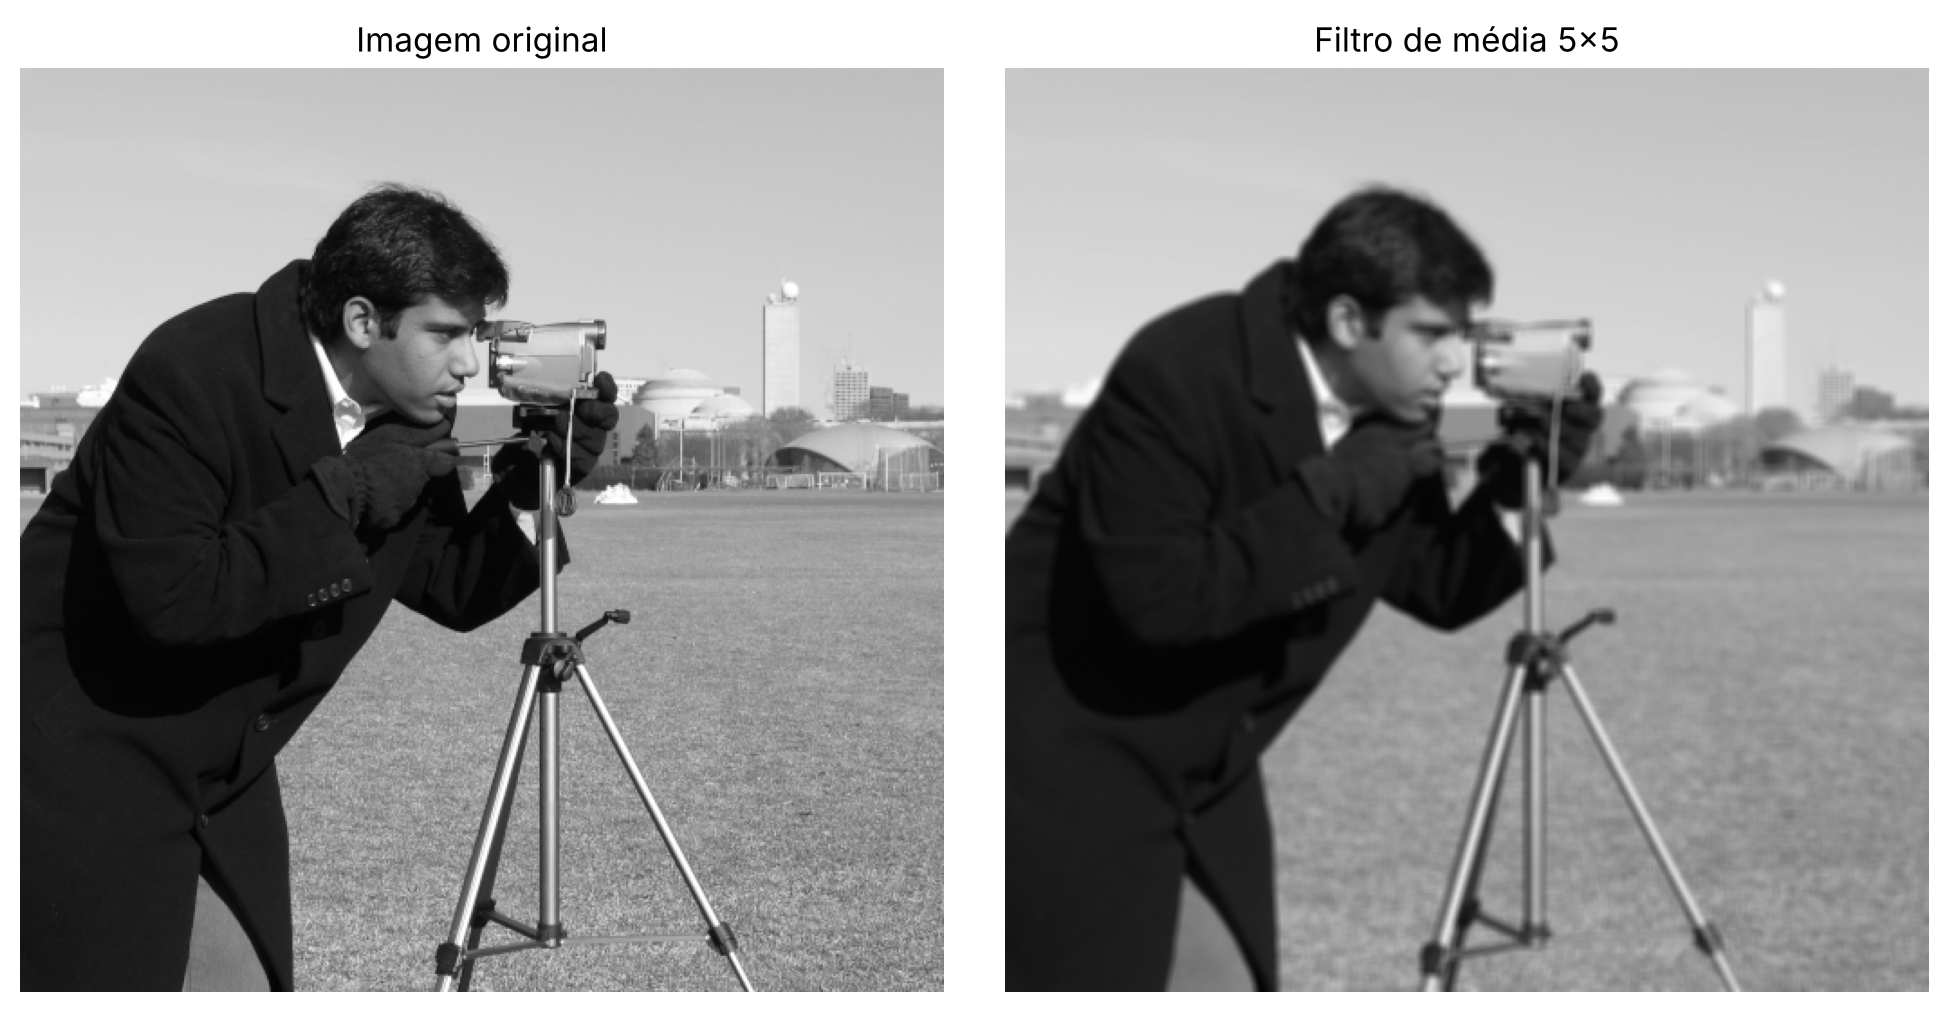

In [10]:
img_media = filtro_media(img_cinza, 5)
comparar(img_cinza, img_media, 'Filtro de média 5x5')

## Filtro de Mediana

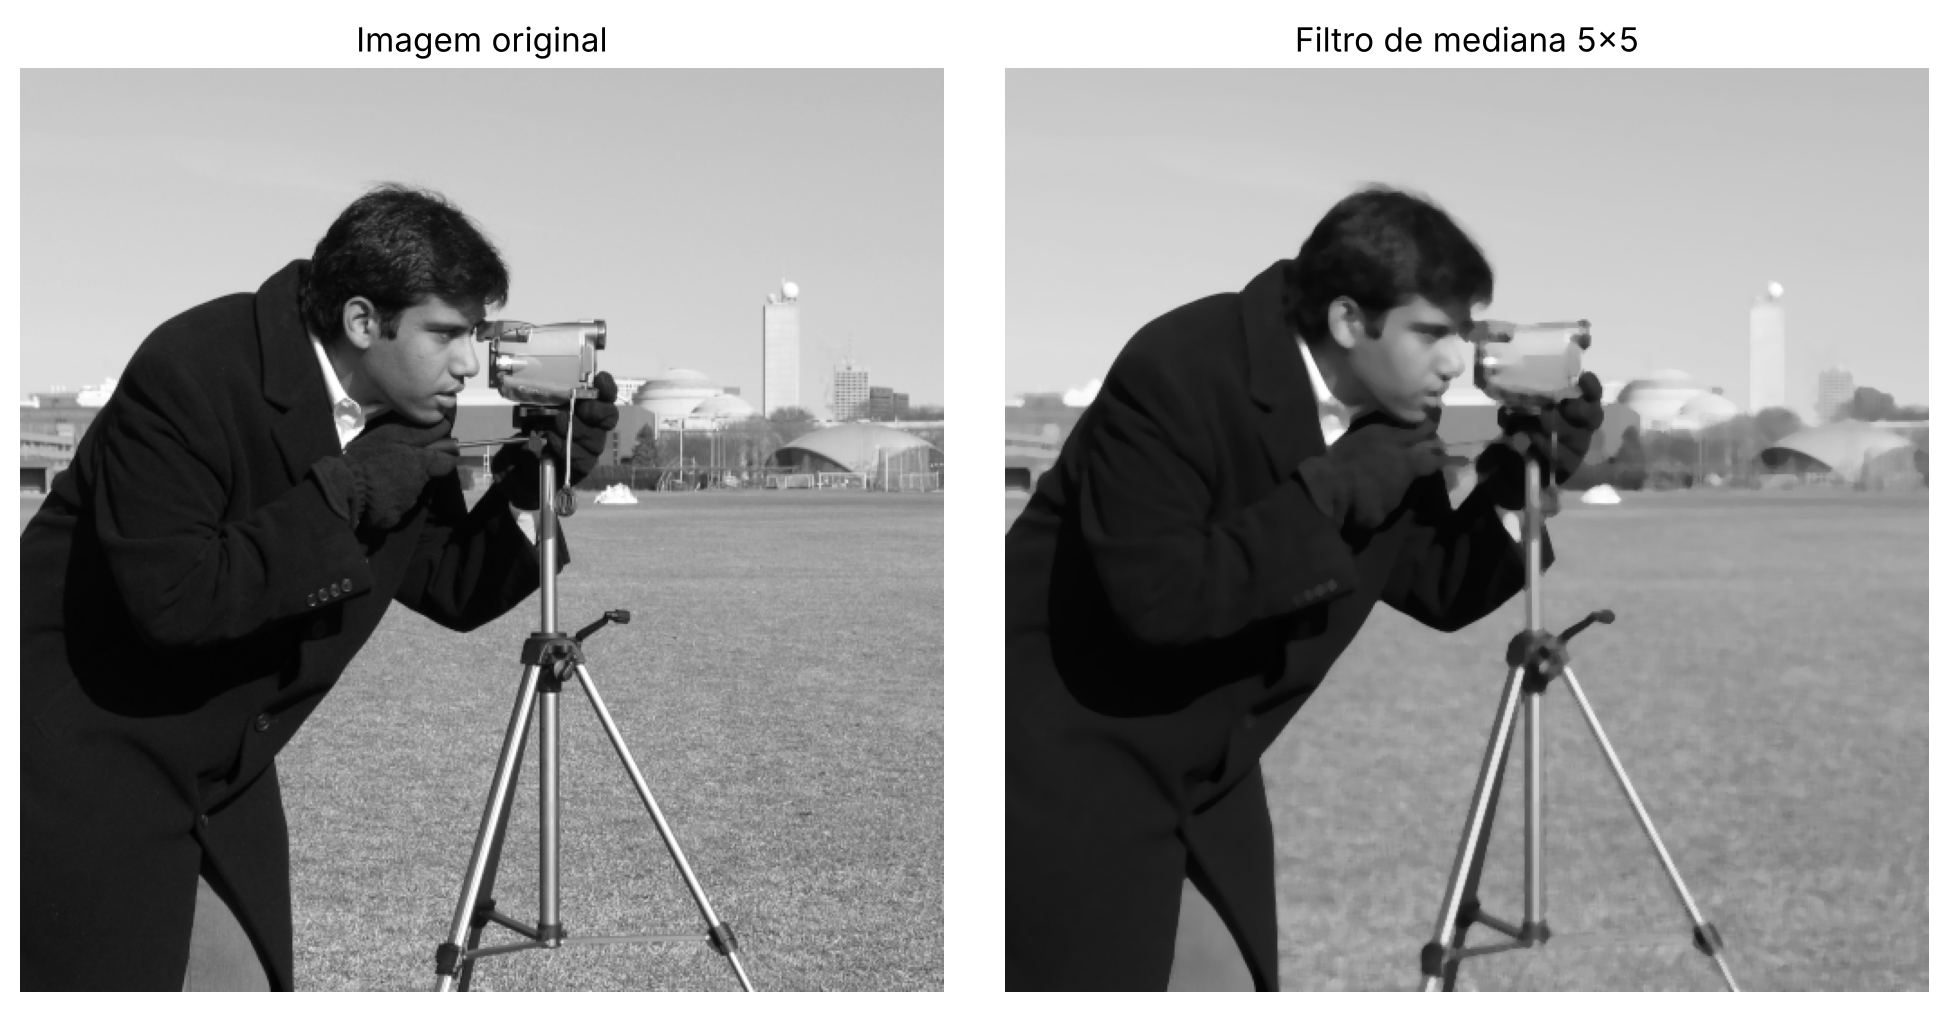

In [11]:
img_mediana = filtro_mediana(img_cinza, 5)
comparar(img_cinza, img_mediana, 'Filtro de mediana 5x5')

## Filtro de Moda

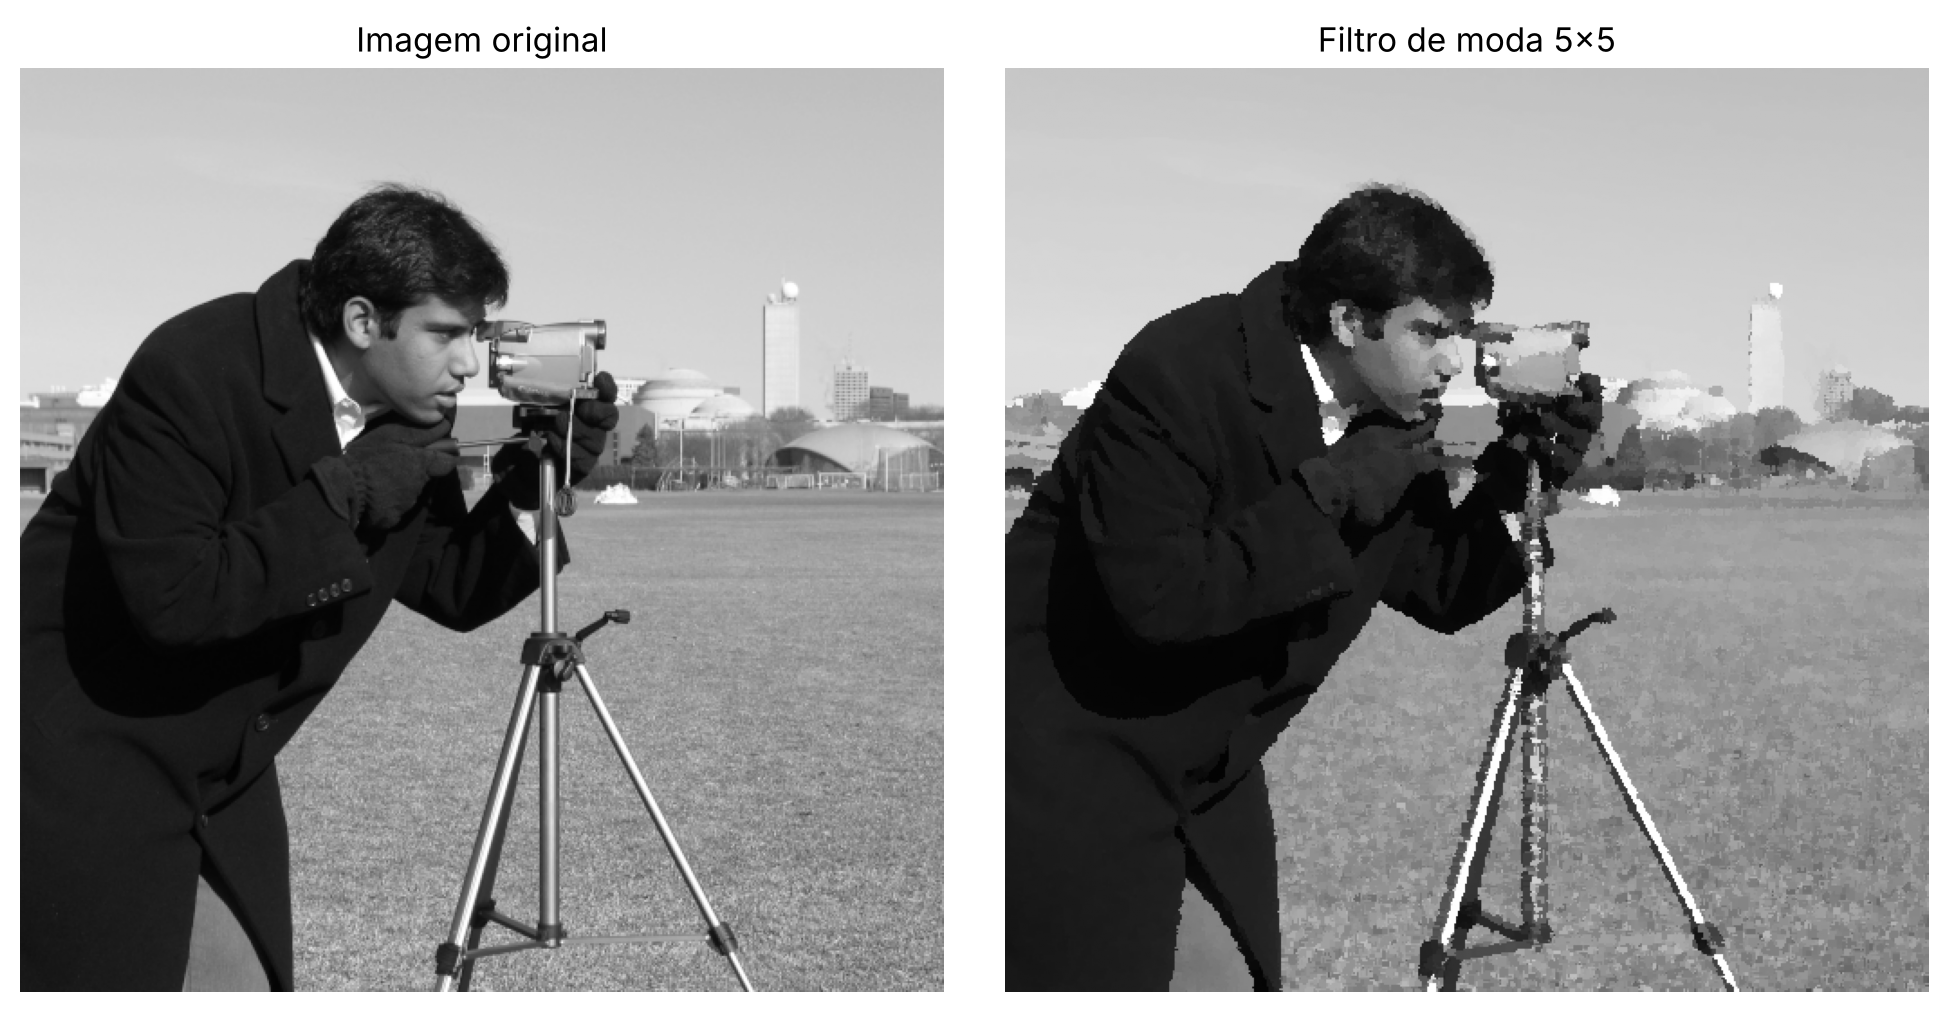

In [12]:
img_moda = filtro_moda(img_cinza, 5)
comparar(img_cinza, img_moda, 'Filtro de moda 5x5')

## Filtro de Máxima

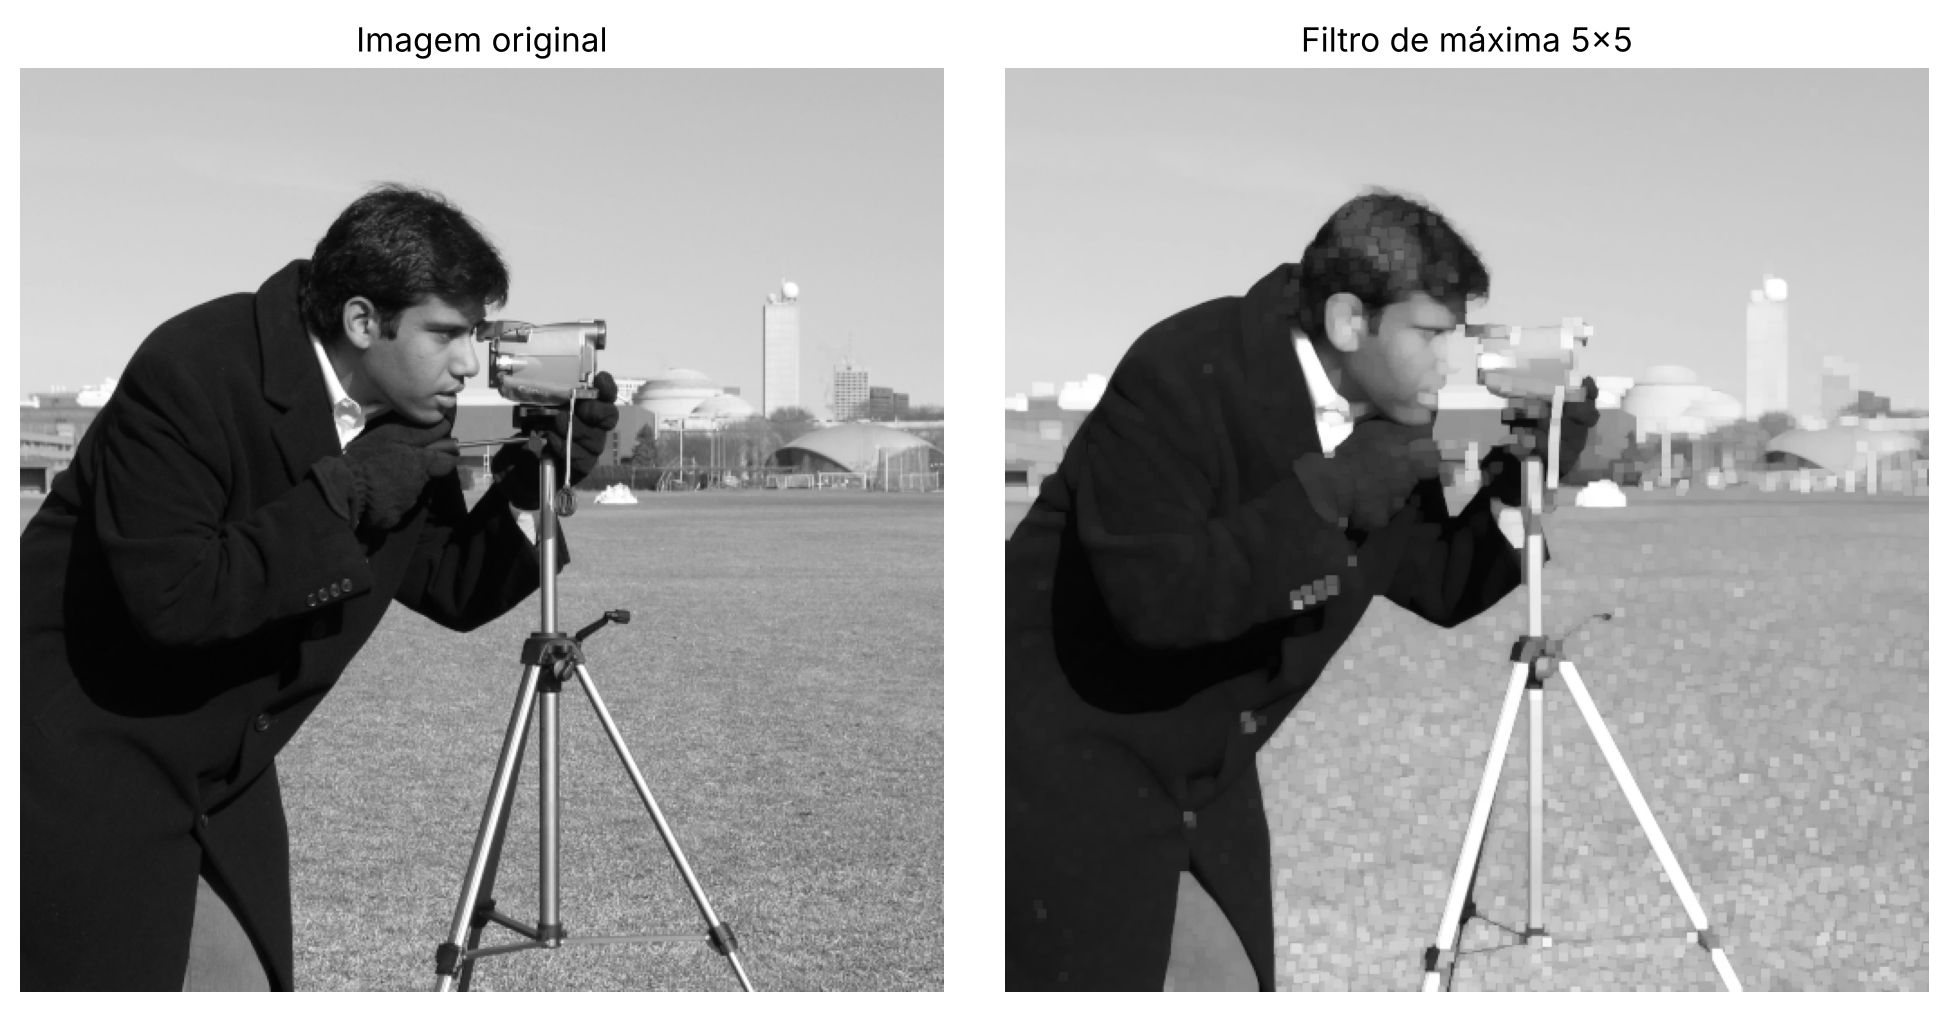

In [13]:
img_maximo = filtro_maximo(img_cinza, 5)
comparar(img_cinza, img_maximo, 'Filtro de máxima 5x5')